In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

In [5]:

df = pd.read_csv("../data/Convolution.csv")

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (35000, 37)


,IT,batchsize,matsize,kernelsize,channels_in,channels_out,strides,padding,precision,activation_fct,...,TMUs,ROPs,SM,TC,RT,PR,TR,FP16,FP32,FP64
0,0,18,205,5,11,45,1,same,32,2,...,240,80,60,240,60,163,490,30290,30290,473
1,1,29,297,7,10,27,2,valid,32,0,...,240,80,60,240,60,163,490,30290,30290,473
2,2,11,145,7,6,21,4,valid,32,0,...,240,80,60,240,60,163,490,30290,30290,473
3,3,56,117,7,18,82,2,same,32,1,...,240,80,60,240,60,163,490,30290,30290,473
4,4,15,147,4,9,27,2,valid,32,3,...,240,80,60,240,60,163,490,30290,30290,473


In [6]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (35000, 37)

Column names:
['IT', 'batchsize', 'matsize', 'kernelsize', 'channels_in', 'channels_out', 'strides', 'padding', 'precision', 'activation_fct', 'use_bias', 'optimizer', 'timeUsed_median', 'timeUsed_min', 'timeUsed_max', 'timeUsed_std', 'GPU', 'Provisioning', 'Base Clock (MHz)', 'Boost Clock (MHz)', 'Memory Clock (MHz)', 'Memory (GB)', 'Memory Type', 'Memory Bus (bit)', 'GPU Memory Bandwidth (GB/s)', 'Bus', 'Cores', 'TMUs', 'ROPs', 'SM', 'TC', 'RT', 'PR', 'TR', 'FP16', 'FP32', 'FP64']


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 35000 entries, 0 to 34999
Data columns (total 37 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   IT                           35000 non-null  int64  
 1   batchsize                    35000 non-null  int64  
 2   matsize                      35000 non-null  int64  
 3   kernelsize                   35000 non-null  int64  
 4   channels_in                  35000 non-null  int64  
 5   channels_out                 35000 non-null  int64  
 6   strides                      35000 non-null  int64  
 7   padding                      35000 non-null  str    
 8   precision                    35000 non-null  int64  
 9   activation_fct               35000 non-null  int64  
 10  use_bias                     35000 non-null  bool   
 11  optimizer                    35000 non-null  int64  
 12  timeUsed_median              35000 non-null  float64
 13  timeUsed_min               

In [8]:
df.head().T

,0,1,2,3,4
IT,0,1,2,3,4
batchsize,18,29,11,56,15
matsize,205,297,145,117,147
kernelsize,5,7,7,7,4
channels_in,11,10,6,18,9
channels_out,45,27,21,82,27
strides,1,2,4,2,2
padding,same,valid,valid,same,valid
precision,32,32,32,32,32
activation_fct,2,0,0,1,3


In [9]:

for col in df.columns:
    print(f"{col:30} | unique values: {df[col].nunique():5}")


IT                             | unique values:  5001
batchsize                      | unique values:    64
matsize                        | unique values:   512
kernelsize                     | unique values:     7
channels_in                    | unique values:  1016
channels_out                   | unique values:  1013
strides                        | unique values:     4
padding                        | unique values:     2
precision                      | unique values:     1
activation_fct                 | unique values:     4
use_bias                       | unique values:     2
optimizer                      | unique values:     6
timeUsed_median                | unique values: 34794
timeUsed_min                   | unique values: 34611
timeUsed_max                   | unique values: 34547
timeUsed_std                   | unique values: 18056
GPU                            | unique values:     7
Provisioning                   | unique values:     2
Base Clock (MHz)            

In [10]:
categorical_check = [
    "padding",
    "precision",
    "activation_fct",
    "use_bias",
    "optimizer",
    "GPU",
    "Provisioning",
    "Memory Type",
    "Bus"
]

for col in categorical_check:
    print("\n" + "=" * 50)
    print(col)
    print(df[col].value_counts().sort_index())


padding
padding
same     17460
valid    17540
Name: count, dtype: int64

precision
precision
32    35000
Name: count, dtype: int64

activation_fct
activation_fct
0    8806
1    8649
2    8691
3    8854
Name: count, dtype: int64

use_bias
use_bias
False    17392
True     17608
Name: count, dtype: int64

optimizer
optimizer
0    17447
1     3576
2     3526
3     3461
4     3441
5     3549
Name: count, dtype: int64

GPU
GPU
L4          5000
P100        5000
P4          5000
RTX4090     5000
RTXA4000    5000
T4          5000
V100        5000
Name: count, dtype: int64

Provisioning
Provisioning
Cloud    25000
Local    10000
Name: count, dtype: int64

Memory Type
Memory Type
GDDR6     15000
GDDR6X     5000
HBM2      15000
Name: count, dtype: int64

Bus
Bus
PCIe 3.0    20000
PCIe 4.0    15000
Name: count, dtype: int64


In [11]:
print("GPU distribution:")
print(df["GPU"].value_counts())

print("\nProvisioning:")
print(df["Provisioning"].value_counts())

print("\nPrecision:")
print(df["precision"].value_counts())

GPU distribution:
GPU
L4          5000
P4          5000
P100        5000
RTX4090     5000
RTXA4000    5000
T4          5000
V100        5000
Name: count, dtype: int64

Provisioning:
Provisioning
Cloud    25000
Local    10000
Name: count, dtype: int64

Precision:
precision
32    35000
Name: count, dtype: int64


In [12]:
target = "timeUsed_median"

drop_columns = [
    "IT",
    "precision",
    "timeUsed_median",
    "timeUsed_min",
    "timeUsed_max",
    "timeUsed_std"
]

X = df.drop(columns=drop_columns)
y = df[target]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (35000, 31)
Target: (35000,)


In [13]:
categorical_features = [
    "padding",
    "activation_fct",
    "use_bias",
    "optimizer",
    "GPU",
    "Provisioning",
    "Memory Type",
    "Bus"
]

numeric_features = [
    col for col in X.columns
    if col not in categorical_features
]

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numeric_features)

Categorical features:
['padding', 'activation_fct', 'use_bias', 'optimizer', 'GPU', 'Provisioning', 'Memory Type', 'Bus']

Numerical features:
['batchsize', 'matsize', 'kernelsize', 'channels_in', 'channels_out', 'strides', 'Base Clock (MHz)', 'Boost Clock (MHz)', 'Memory Clock (MHz)', 'Memory (GB)', 'Memory Bus (bit)', 'GPU Memory Bandwidth (GB/s)', 'Cores', 'TMUs', 'ROPs', 'SM', 'TC', 'RT', 'PR', 'TR', 'FP16', 'FP32', 'FP64']


In [14]:
print(y.describe())

print("\nMinimum runtime:", y.min())
print("Maximum runtime:", y.max())
print("Median runtime:", y.median())

count    35000.000000
mean         8.902356
std         22.560351
min          0.048685
25%          0.950772
50%          2.805680
75%          7.541772
max        682.360370
Name: timeUsed_median, dtype: float64

Minimum runtime: 0.048685074
Maximum runtime: 682.3603702
Median runtime: 2.8056800365


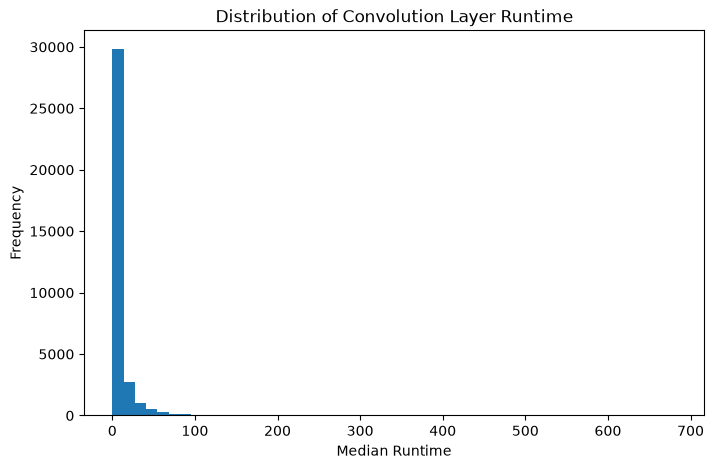

In [15]:
plt.figure(figsize=(8, 5))

plt.hist(y, bins=50)

plt.xlabel("Median Runtime")
plt.ylabel("Frequency")
plt.title("Distribution of Convolution Layer Runtime")

plt.show()

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 28000
Testing samples: 7000


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

In [18]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

In [19]:
from sklearn.pipeline import Pipeline

baseline_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("model", rf_model)
    ]
)

In [20]:
print("Training Iteration 1 model...")

baseline_pipeline.fit(
    X_train,
    y_train
)

print("Training complete.")

Training Iteration 1 model...
Training complete.


In [21]:
y_pred = baseline_pipeline.predict(X_test)

print("Predictions generated:", len(y_pred))

print("\nFirst 10 predictions:")
print(y_pred[:10])

Predictions generated: 7000

First 10 predictions:
[ 0.44802811 10.72934229  5.00270624 14.59912987  1.06294402  5.69748812
  8.31025419  2.78721507  2.08292788  4.12959986]


In [22]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

mape = mean_absolute_percentage_error(
    y_test,
    y_pred
) * 100

r2 = r2_score(
    y_test,
    y_pred
)

print("ITERATION 1 — RANDOM FOREST BASELINE")
print("=" * 45)
print(f"MAE  : {mae:.6f}")
print(f"RMSE : {rmse:.6f}")
print(f"MAPE : {mape:.2f}%")
print(f"R²   : {r2:.6f}")

ITERATION 1 — RANDOM FOREST BASELINE
MAE  : 2.694046
RMSE : 8.822769
MAPE : 51.05%
R²   : 0.874804


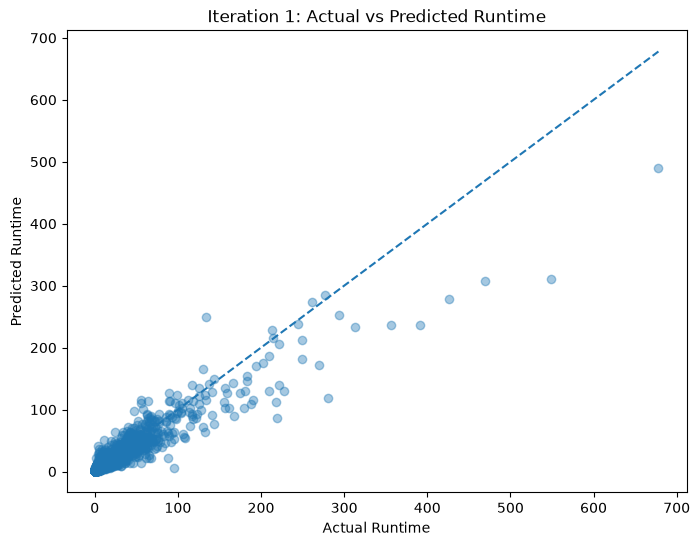

In [23]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.4
)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Runtime")
plt.ylabel("Predicted Runtime")
plt.title("Iteration 1: Actual vs Predicted Runtime")

plt.show()

In [24]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

results["Absolute_Error"] = (
    abs(results["Actual"] - results["Predicted"])
)

results["Percentage_Error"] = (
    results["Absolute_Error"] /
    results["Actual"]
) * 100

results.head(10)

,Actual,Predicted,Absolute_Error,Percentage_Error
0,0.385754,0.448028,0.062274,16.143445
1,7.164865,10.729342,3.564478,49.749409
2,3.160284,5.002706,1.842423,58.299283
3,15.480204,14.599130,0.881074,5.691616
4,0.735073,1.062944,0.327871,44.603854
5,4.043467,5.697488,1.654021,40.906011
6,7.663043,8.310254,0.647212,8.445884
7,2.110124,2.787215,0.677091,32.087761
8,2.670238,2.082928,0.587310,21.994674
9,3.112054,4.129600,1.017546,32.696927


In [25]:
results["Absolute_Error"].describe()

count    7000.000000
mean        2.694046
std         8.401991
min         0.000094
25%         0.216116
50%         0.693621
75%         2.222207
max       238.351997
Name: Absolute_Error, dtype: float64

In [26]:
feature_names = (
    baseline_pipeline
    .named_steps["preprocessing"]
    .get_feature_names_out()
)

importances = (
    baseline_pipeline
    .named_steps["model"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

importance_df.head(20)

,Feature,Importance
1,num__matsize,0.182541
2,num__kernelsize,0.136356
0,num__batchsize,0.129195
5,num__strides,0.107943
3,num__channels_in,0.096455
31,cat__optimizer_0,0.091563
39,cat__GPU_P4,0.037840
4,num__channels_out,0.029440
38,cat__GPU_P100,0.023944
21,num__FP32,0.019294


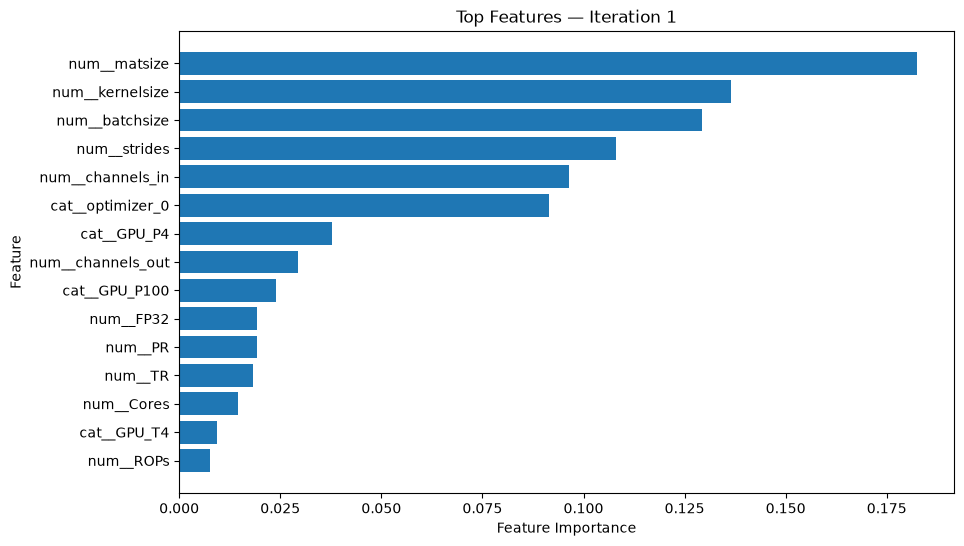

In [27]:
top_features = importance_df.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top Features — Iteration 1")

plt.show()

In [28]:
df_iter2 = df.copy()

print(df_iter2.shape)

(35000, 37)


In [29]:
df_iter2["parameter_count"] = (
    df_iter2["kernelsize"] ** 2
    * df_iter2["channels_in"]
    * df_iter2["channels_out"]
)

df_iter2["output_spatial_size"] = (
    df_iter2["matsize"] ** 2
)

df_iter2["estimated_macs"] = (
    df_iter2["batchsize"]
    * df_iter2["output_spatial_size"]
    * df_iter2["channels_in"]
    * df_iter2["channels_out"]
    * df_iter2["kernelsize"] ** 2
)

df_iter2["estimated_flops"] = (
    2 * df_iter2["estimated_macs"]
)

print(
    df_iter2[
        [
            "parameter_count",
            "output_spatial_size",
            "estimated_macs",
            "estimated_flops"
        ]
    ].head()
)

   parameter_count  output_spatial_size  estimated_macs  estimated_flops
0            12375                42025      9361068750      18722137500
1            13230                88209     33843147030      67686294060
2             6174                21025      1427891850       2855783700
3            72324                13689     55442421216     110884842432
4             3888                21609      1260236880       2520473760


In [30]:
df_iter2[
    [
        "batchsize",
        "matsize",
        "kernelsize",
        "channels_in",
        "channels_out",
        "parameter_count",
        "estimated_macs",
        "estimated_flops",
        "timeUsed_median"
    ]
].head(10)

,batchsize,matsize,kernelsize,channels_in,channels_out,parameter_count,estimated_macs,estimated_flops,timeUsed_median
0,18,205,5,11,45,12375,9361068750,18722137500,4.948092
1,29,297,7,10,27,13230,33843147030,67686294060,4.745879
2,11,145,7,6,21,6174,1427891850,2855783700,0.931890
3,56,117,7,18,82,72324,55442421216,110884842432,13.542883
4,15,147,4,9,27,3888,1260236880,2520473760,1.053717
5,5,209,1,21,43,903,197219715,394439430,0.927918
6,23,330,6,8,16,4608,11541657600,23083315200,1.550875
7,43,378,6,13,17,7956,48881759472,97763518944,34.332833
8,48,387,4,21,23,7728,55555911936,111111823872,33.446047
9,25,43,1,49,201,9849,455270025,910540050,0.095456


In [31]:
correlation_features = [
    "batchsize",
    "matsize",
    "kernelsize",
    "channels_in",
    "channels_out",
    "parameter_count",
    "estimated_macs",
    "estimated_flops",
    "timeUsed_median"
]

correlation_matrix = (
    df_iter2[correlation_features]
    .corr()
)

correlation_matrix["timeUsed_median"].sort_values(
    ascending=False
)

timeUsed_median    1.000000
estimated_macs     0.321285
estimated_flops    0.321285
batchsize          0.213439
matsize            0.189109
kernelsize         0.182219
parameter_count   -0.008168
channels_in       -0.026644
channels_out      -0.028489
Name: timeUsed_median, dtype: float64

In [32]:
target = "timeUsed_median"

drop_columns = [
    "IT",
    "precision",
    "timeUsed_median",
    "timeUsed_min",
    "timeUsed_max",
    "timeUsed_std"
]

X2 = df_iter2.drop(columns=drop_columns)
y2 = df_iter2[target]

print("X2 shape:", X2.shape)
print("y2 shape:", y2.shape)

X2 shape: (35000, 35)
y2 shape: (35000,)


In [33]:
categorical_features_2 = [
    "padding",
    "activation_fct",
    "use_bias",
    "optimizer",
    "GPU",
    "Provisioning",
    "Memory Type",
    "Bus"
]

numeric_features_2 = [
    col for col in X2.columns
    if col not in categorical_features_2
]

print("Numerical features:", len(numeric_features_2))
print("Categorical features:", len(categorical_features_2))

Numerical features: 27
Categorical features: 8


In [34]:
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2,
    y2,
    test_size=0.20,
    random_state=42
)

print("Training:", len(X2_train))
print("Testing :", len(X2_test))

Training: 28000
Testing : 7000


In [35]:
preprocessor_2 = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            numeric_features_2
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features_2
        )
    ]
)

In [36]:
rf_model_2 = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

In [38]:
iteration2_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor_2),
        ("model", rf_model_2)
    ]
)

In [39]:
print("Training Iteration 2...")

iteration2_pipeline.fit(
    X2_train,
    y2_train
)

print("Training complete.")

Training Iteration 2...
Training complete.


In [40]:
y2_pred = iteration2_pipeline.predict(X2_test)

print("Predictions generated:", len(y2_pred))

Predictions generated: 7000


In [41]:
mae_2 = mean_absolute_error(y2_test, y2_pred)

rmse_2 = np.sqrt(
    mean_squared_error(y2_test, y2_pred)
)

mape_2 = mean_absolute_percentage_error(
    y2_test,
    y2_pred
) * 100

r2_2 = r2_score(
    y2_test,
    y2_pred
)

print("ITERATION 2 — WORKLOAD-AWARE RANDOM FOREST")
print("=" * 50)
print(f"MAE  : {mae_2:.6f}")
print(f"RMSE : {rmse_2:.6f}")
print(f"MAPE : {mape_2:.2f}%")
print(f"R²   : {r2_2:.6f}")

ITERATION 2 — WORKLOAD-AWARE RANDOM FOREST
MAE  : 2.130142
RMSE : 7.836441
MAPE : 31.38%
R²   : 0.901232


In [42]:
comparison = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "MAPE", "R²"],
    "Iteration 1": [
        mae,
        rmse,
        mape,
        r2
    ],
    "Iteration 2": [
        mae_2,
        rmse_2,
        mape_2,
        r2_2
    ]
})

comparison

,Metric,Iteration 1,Iteration 2
0,MAE,2.694046,2.130142
1,RMSE,8.822769,7.836441
2,MAPE,51.046179,31.375632
3,R²,0.874804,0.901232


In [43]:
comparison["Change (%)"] = (
    (comparison["Iteration 2"] - comparison["Iteration 1"])
    / comparison["Iteration 1"]
) * 100

comparison

,Metric,Iteration 1,Iteration 2,Change (%)
0,MAE,2.694046,2.130142,-20.931477
1,RMSE,8.822769,7.836441,-11.179344
2,MAPE,51.046179,31.375632,-38.534808
3,R²,0.874804,0.901232,3.020950


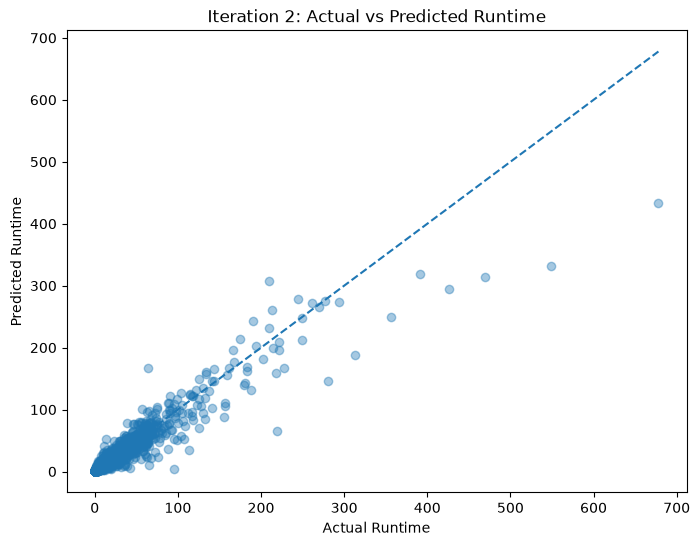

In [44]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y2_test,
    y2_pred,
    alpha=0.4
)

min_value = min(y2_test.min(), y2_pred.min())
max_value = max(y2_test.max(), y2_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Runtime")
plt.ylabel("Predicted Runtime")
plt.title("Iteration 2: Actual vs Predicted Runtime")

plt.show()

In [45]:
# Iteration 2 — Error Analysis

errors_2 = pd.DataFrame({
    "Actual": y2_test.values,
    "Predicted": y2_pred,
})

errors_2["Absolute_Error"] = (
    errors_2["Actual"] - errors_2["Predicted"]
).abs()

errors_2["Percentage_Error"] = (
    errors_2["Absolute_Error"] / errors_2["Actual"]
) * 100

print("ITERATION 2 — ERROR ANALYSIS")
print("=" * 50)

print("\nLargest absolute errors:")
display(
    errors_2
    .sort_values("Absolute_Error", ascending=False)
    .head(10)
)

print("\nError statistics:")
print(errors_2["Absolute_Error"].describe())

ITERATION 2 — ERROR ANALYSIS

Largest absolute errors:


,Actual,Predicted,Absolute_Error,Percentage_Error
1121,678.039184,433.540831,244.498352,36.059620
6155,548.603187,331.823896,216.779290,39.514771
4399,468.892195,313.372641,155.519554,33.167444
5731,218.834758,66.122887,152.711871,69.784102
4186,280.598805,146.894399,133.704406,47.649671
3138,426.395342,294.447250,131.948093,30.945013
2958,313.570516,187.672437,125.898079,40.149846
2994,356.494131,249.634955,106.859176,29.975017
299,63.613150,166.385178,102.772028,161.557834
213,209.579174,307.459009,97.879835,46.703035



Error statistics:
count    7000.000000
mean        2.130142
std         7.541912
min         0.000058
25%         0.151812
50%         0.507340
75%         1.618142
max       244.498352
Name: Absolute_Error, dtype: float64


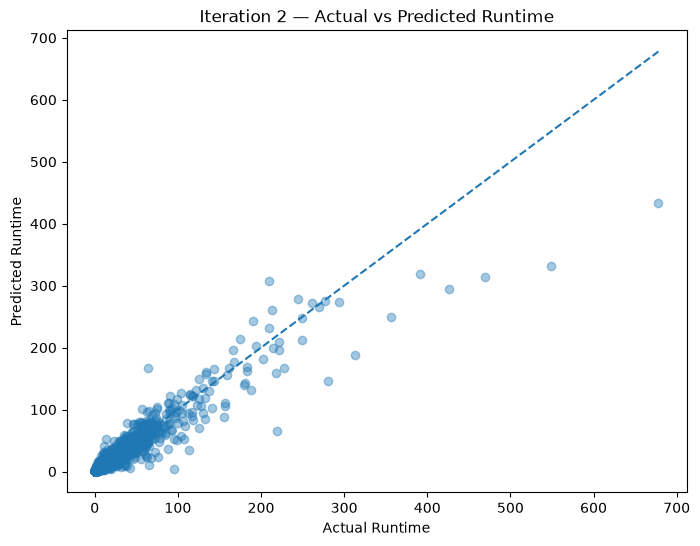

In [46]:
plt.figure(figsize=(8, 6))

plt.scatter(
    errors_2["Actual"],
    errors_2["Predicted"],
    alpha=0.4
)

min_val = min(errors_2["Actual"].min(), errors_2["Predicted"].min())
max_val = max(errors_2["Actual"].max(), errors_2["Predicted"].max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Actual Runtime")
plt.ylabel("Predicted Runtime")
plt.title("Iteration 2 — Actual vs Predicted Runtime")
plt.show()

In [47]:
# Iteration 3 — Log-transformed target

y2_train_log = np.log1p(y2_train)
y2_test_log = np.log1p(y2_test)

print("Original target range:")
print(y2_train.min(), "to", y2_train.max())

print("\nLog-transformed target range:")
print(y2_train_log.min(), "to", y2_train_log.max())

Original target range:
0.049786568 to 682.3603702

Log-transformed target range:
0.048586874936147384 to 6.527022348827966


In [48]:
rf_model_3 = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

iteration3_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor_2),
        ("model", rf_model_3)
    ]
)

In [49]:
iteration3_pipeline.fit(
    X2_train,
    y2_train_log
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](35,)","['batchsize','matsize','kernelsize',...,'output_spatial_size', 'estimated_macs','estimated_flops']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,35
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed thr

In [50]:
y3_pred_log = iteration3_pipeline.predict(X2_test)

# Convert predictions back to the original runtime scale
y3_pred = np.expm1(y3_pred_log)

In [51]:
mae_3 = mean_absolute_error(y2_test, y3_pred)

rmse_3 = np.sqrt(
    mean_squared_error(y2_test, y3_pred)
)

mape_3 = (
    mean_absolute_percentage_error(y2_test, y3_pred) * 100
)

r2_3 = r2_score(
    y2_test,
    y3_pred
)

print("ITERATION 3 — LOG-TARGET RANDOM FOREST")
print("=" * 50)
print(f"MAE  : {mae_3:.6f}")
print(f"RMSE : {rmse_3:.6f}")
print(f"MAPE : {mape_3:.2f}%")
print(f"R²   : {r2_3:.6f}")

ITERATION 3 — LOG-TARGET RANDOM FOREST
MAE  : 2.050969
RMSE : 8.215312
MAPE : 25.41%
R²   : 0.891451


In [52]:
comparison_all = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "MAPE", "R²"],
    "Iteration 1": [mae, rmse, mape, r2],
    "Iteration 2": [mae_2, rmse_2, mape_2, r2_2],
    "Iteration 3": [mae_3, rmse_3, mape_3, r2_3]
})

comparison_all

,Metric,Iteration 1,Iteration 2,Iteration 3
0,MAE,2.694046,2.130142,2.050969
1,RMSE,8.822769,7.836441,8.215312
2,MAPE,51.046179,31.375632,25.409806
3,R²,0.874804,0.901232,0.891451


In [53]:
from sklearn.model_selection import RandomizedSearchCV

rf_param_grid = {
    "model__n_estimators": [200, 300, 500],
    "model__max_depth": [None, 15, 20, 30],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [1.0, "sqrt", "log2"]
}

rf_tuning_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor_2),
        ("model", RandomForestRegressor(
            random_state=42,
            n_jobs=-1
        ))
    ]
)

random_search = RandomizedSearchCV(
    estimator=rf_tuning_pipeline,
    param_distributions=rf_param_grid,
    n_iter=15,
    scoring="neg_root_mean_squared_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [61]:
random_search.fit(X2_train, y2_train)

print("BEST PARAMETERS")
print("=" * 50)

for parameter, value in random_search.best_params_.items():
    print(f"{parameter}: {value}")

print("\nBest CV RMSE:")
print(-random_search.best_score_)

Fitting 3 folds for each of 15 candidates, totalling 45 fits
BEST PARAMETERS
model__n_estimators: 500
model__min_samples_split: 2
model__min_samples_leaf: 1
model__max_features: 1.0
model__max_depth: 20

Best CV RMSE:
7.941780306164561


In [62]:
iteration4_model = random_search.best_estimator_

y4_pred = iteration4_model.predict(X2_test)

mae_4 = mean_absolute_error(y2_test, y4_pred)

rmse_4 = np.sqrt(
    mean_squared_error(y2_test, y4_pred)
)

mape_4 = (
    mean_absolute_percentage_error(y2_test, y4_pred) * 100
)

r2_4 = r2_score(
    y2_test,
    y4_pred
)

print("ITERATION 4 — TUNED RANDOM FOREST")
print("=" * 50)
print(f"MAE  : {mae_4:.6f}")
print(f"RMSE : {rmse_4:.6f}")
print(f"MAPE : {mape_4:.2f}%")
print(f"R²   : {r2_4:.6f}")

ITERATION 4 — TUNED RANDOM FOREST
MAE  : 2.135462
RMSE : 7.844548
MAPE : 31.23%
R²   : 0.901027


In [63]:
final_comparison = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "MAPE", "R²"],
    "Iteration 1": [mae, rmse, mape, r2],
    "Iteration 2": [mae_2, rmse_2, mape_2, r2_2],
    "Iteration 3": [mae_3, rmse_3, mape_3, r2_3],
    "Iteration 4": [mae_4, rmse_4, mape_4, r2_4]
})

final_comparison

,Metric,Iteration 1,Iteration 2,Iteration 3,Iteration 4
0,MAE,2.694046,2.130142,2.050969,2.135462
1,RMSE,8.822769,7.836441,8.215312,7.844548
2,MAPE,51.046179,31.375632,25.409806,31.233318
3,R²,0.874804,0.901232,0.891451,0.901027


In [66]:
import joblib

joblib.dump(
    iteration2_pipeline,
    "../models/runtime_model.pkl"
)

print("Model saved successfully.")

Model saved successfully.


In [65]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

joblib.dump(
    iteration2_pipeline,
    "../models/runtime_model.pkl"
)

print("Model saved successfully.")

Model saved successfully.
